# Задание 4.17

В кубе объёма 1 случайным образом выбираются точки $A$, $B$ и $C$. Пусть $R$, $S$ и $T$ — события, состоящие в том, что: $R$ — наименьший угол в треугольнике $ABC$ меньше $26{,}7^\circ$; $S$ — наибольший угол в треугольнике $ABC$ меньше $81{,}9^\circ$; $T$ — треугольник $ABC$ остроугольный. Найдите приближённо, методом Монте-Карло: 1) условную вероятность $\mathbb P(R\mid T)$; 2) условную вероятность $\mathbb P(S\mid T)$. *Указание:* получите 100000 остроугольных треугольников $ABC$ и, используя все эти треугольники, найдите ответы, округляя их до одного знака после запятой.

**Ответ:** 1) $\mathbb P(R\mid T)=0{,}11$; 2) $\mathbb P(S\mid T)=0{,}65$.

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Модель.** Точки $A,B,C$ независимы и равномерны в единичном кубе $[0,1]^3$; $\Omega=([0,1]^3)^3$.

**Углы треугольника** находим через скалярное произведение:

$$
\cos\angle A=\frac{\vec{AB}\cdot\vec{AC}}{|\vec{AB}|\,|\vec{AC}|},\quad
\cos\angle B=\frac{\vec{BA}\cdot\vec{BC}}{|\vec{BA}|\,|\vec{BC}|},\quad
\angle C=180^\circ-\angle A-\angle B .
$$

Треугольник **остроугольный** ($T$) ⇔ все три скалярных произведения в вершинах положительны, т.е. наибольший угол меньше $90^\circ$.

**Условная вероятность методом Монте-Карло.** По определению $\mathbb P(R\mid T)=\dfrac{\mathbb P(RT)}{\mathbb P(T)}$. Генерируем случайные треугольники, отбрасываем неостроугольные, пока не наберётся $N_T=100\,000$ остроугольных. Тогда

$$
\mathbb P(R\mid T)\approx\frac{N(RT)}{N_T},\qquad \mathbb P(S\mid T)\approx\frac{N(ST)}{N_T}.
$$

Это и есть выборка из условного распределения при условии $T$ (метод отбора). Попутно получаем оценку $\mathbb P(T)$ — долю остроугольных среди всех сгенерированных.

Точной формулы нет, поэтому контрольное (красное) значение на графиках берём из отдельной большой выборки ($10^6$ остроугольных треугольников).

Сгенерировано 218689 треугольников, остроугольных 100000: P(T) ≈ 0.457
1) P(R|T) ≈ 0.1114 ≈ 0.11   (контроль по 10^6: 0.1120)
2) P(S|T) ≈ 0.6537 ≈ 0.65   (контроль по 10^6: 0.6541)


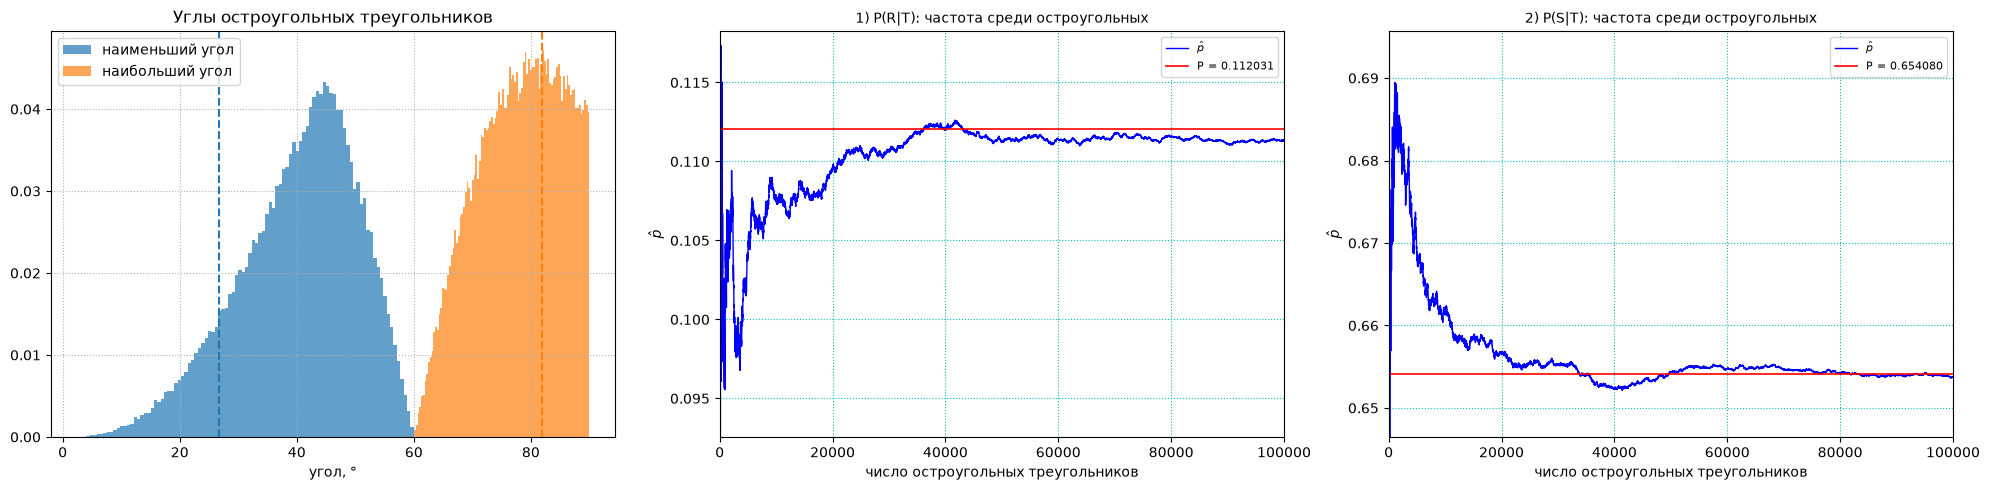

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


def angles(P, Q, Rr):
    """Углы (в градусах) треугольников с вершинами P, Q, R (массивы формы (n, 3))."""
    def ang(X, Y, Z):                      # угол при вершине X
        u, v = Y - X, Z - X
        c = np.einsum("ij,ij->i", u, v) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1))
        return np.degrees(np.arccos(np.clip(c, -1, 1)))
    a, b = ang(P, Q, Rr), ang(Q, P, Rr)
    return np.column_stack([a, b, 180 - a - b])


def acute_triangles(n_needed, batch=400_000):
    """Генерирует случайные треугольники в кубе, пока не наберёт n_needed остроугольных.
    Возвращает их углы и общее число сгенерированных треугольников."""
    got, have, total = [], 0, 0
    while have < n_needed:
        P, Q, Rr = rng.random((3, batch, 3))           # три случайные точки в единичном кубе
        ang = angles(P, Q, Rr)
        idx = np.flatnonzero(ang.max(axis=1) < 90)      # отбор: остроугольные (событие T)
        idx = idx[:n_needed - have]                     # берём ровно столько, сколько не хватает
        got.append(ang[idx])
        have += len(idx)
        total += batch if have < n_needed else idx[-1] + 1   # сколько треугольников реально просмотрено
    return np.vstack(got), total


# ---------- Контроль по большой выборке ----------
ang_ref, _ = acute_triangles(1_000_000)
PR_ref = np.mean(ang_ref.min(axis=1) < 26.7)
PS_ref = np.mean(ang_ref.max(axis=1) < 81.9)

# ---------- Метод Монте-Карло: 100 000 остроугольных треугольников ----------
NT = 100_000
ang, total = acute_triangles(NT)
R = ang.min(axis=1) < 26.7                  # наименьший угол меньше 26.7°
S = ang.max(axis=1) < 81.9                  # наибольший угол меньше 81.9°
print(f"Сгенерировано {total} треугольников, остроугольных {NT}: P(T) ≈ {NT/total:.3f}")
print(f"1) P(R|T) ≈ {R.mean():.4f} ≈ {R.mean():.2f}   (контроль по 10^6: {PR_ref:.4f})")
print(f"2) P(S|T) ≈ {S.mean():.4f} ≈ {S.mean():.2f}   (контроль по 10^6: {PS_ref:.4f})")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].hist(ang.min(axis=1), bins=100, alpha=0.7, density=True, label="наименьший угол")
axes[0].hist(ang.max(axis=1), bins=100, alpha=0.7, density=True, label="наибольший угол")
axes[0].axvline(26.7, color="C0", ls="--"); axes[0].axvline(81.9, color="C1", ls="--")
axes[0].set_xlabel("угол, °"); axes[0].set_title("Углы остроугольных треугольников"); axes[0].legend(); axes[0].grid(ls=":")
plot_freq(axes[1], R, PR_ref, "1) P(R|T): частота среди остроугольных")
plot_freq(axes[2], S, PS_ref, "2) P(S|T): частота среди остроугольных")
for ax in axes[1:]:
    ax.set_xlabel("число остроугольных треугольников")
fig.tight_layout()
plt.show()